<a href="https://colab.research.google.com/github/Gitech247/MODULE_2_ASSESSMENT/blob/main/Module_2_Case_Exercise_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Case Exercise 2: Corrosion Rate Prediction and Remaining Life**

# **Question 1**:
Implement the de Waard-Milliams corrosion rate model with unit tests.

# de Waard-Milliams CO2 Corrosion Rate Model
This notebook implements the empirical **de Waard-Milliams model** to predict the internal corrosion rate of carbon steel pipelines exposed to wet carbon dioxide ($CO_2$) environments.

### Key Equations:
1. **CO₂ Fugacity ($f_{CO_2}$)**: Accounts for gas non-ideality at elevated pressures.
   $$f_{CO_2} = a \cdot P_{CO_2}$$
2. **Nominal Corrosion Rate ($v$)**:
   $$\log_{10}(v) = 5.8 - \frac{1710}{T + 273.15} + 0.67 \log_{10}(f_{CO_2})$$
3. **Scaling Factor ($F_{scale}$)**: Adjusts for protective iron carbonate scale formation at higher temperatures ($T \ge 60^\circ\text{C}$).

In [25]:
import numpy as np

def calculate_fugacity_coefficient(temperature_c: float, total_pressure_bar: float) -> float:
    """
    Calculates the CO2 fugacity coefficient (a) based on temperature and total pressure.
    log10(a) = P_total * (0.0031 - 1.4 / (T + 273.15))
    """
    t_kelvin = temperature_c + 273.15
    log_a = total_pressure_bar * (0.0031 - (1.4 / t_kelvin))
    return float(10**log_a)

def calculate_co2_fugacity(co2_partial_pressure_bar: float, temperature_c: float, total_pressure_bar: float = None) -> float:
    """
    Calculates CO2 fugacity (f_CO2). If total pressure is provided, corrects for non-ideality.
    Otherwise, assumes ideal gas behavior (f_CO2 = P_CO2).
    """
    if total_pressure_bar is None:
        return co2_partial_pressure_bar
    a = calculate_fugacity_coefficient(temperature_c, total_pressure_bar)
    return a * co2_partial_pressure_bar

def calculate_nominal_corrosion_rate(temperature_c: float, f_co2: float) -> float:
    """
    Calculates the nominal de Waard-Milliams corrosion rate in mm/year.
    log10(v) = 5.8 - (1710 / (T + 273.15)) + 0.67 * log10(f_CO2)
    """
    if f_co2 <= 0:
        return 0.0
    t_kelvin = temperature_c + 273.15
    log_v = 5.8 - (1710.0 / t_kelvin) + 0.67 * np.log10(f_co2)
    return float(10**log_v)

def calculate_scaling_factor(temperature_c: float) -> float:
    """
    Calculates the scaling factor F(scale). Below 60°C, no protective scale is assumed (F = 1.0).
    At higher temperatures, scale formation reduces the corrosion rate.
    """
    if temperature_c < 60.0:
        return 1.0
    t_kelvin = temperature_c + 273.15
    log_fs = (2500.0 / t_kelvin) - 7.5
    return float(10**log_fs)

def predict_corrosion_rate(temperature_c: float, co2_partial_pressure_bar: float, total_pressure_bar: float = None) -> dict:
    """
    Executes the complete de Waard-Milliams prediction workflow.
    Returns a dictionary containing intermediate parameters and the final predicted corrosion rate.
    """
    f_co2 = calculate_co2_fugacity(co2_partial_pressure_bar, temperature_c, total_pressure_bar)
    v_nom = calculate_nominal_corrosion_rate(temperature_c, f_co2)
    f_scale = calculate_scaling_factor(temperature_c)

    # Note: In standard applications, scale factor can modify nominal rate depending on specific guidelines.
    final_cr = v_nom  # Base uninhibited rate; apply f_scale if required by specific standard variant.

    return {
        "temperature_c": temperature_c,
        "co2_partial_pressure_bar": co2_partial_pressure_bar,
        "f_co2": f_co2,
        "nominal_corrosion_rate_mm_yr": v_nom,
        "scaling_factor": f_scale,
        "predicted_corrosion_rate_mm_yr": final_cr
    }

# Example calculation
result = predict_corrosion_rate(temperature_c=48.0, co2_partial_pressure_bar=0.6533, total_pressure_bar=16.33)
print("--- Example Prediction Result ---")
for k, v in result.items():
    print(f"{k}: {v:.4f}" if isinstance(v, float) else f"{k}: {v}")


import unittest

class TestDeWaardMilliamsModel(unittest.TestCase):

    def test_ideal_fugacity(self):
        # When total pressure is None, fugacity should equal partial pressure
        f = calculate_co2_fugacity(1.2, 30.0, total_pressure_bar=None)
        self.assertEqual(f, 1.2)

    def test_fugacity_non_ideal(self):
        # Test non-ideal gas correction coefficient at a given condition
        f = calculate_co2_fugacity(0.6533, 48.0, total_pressure_bar=16.33)
        self.assertTrue(0.0 < f < 0.6533)  # Fugacity is typically less than partial pressure at high pressures

    def test_nominal_corrosion_rate(self):
        # At T = 20°C (293.15 K) and f_CO2 = 1.0 bar:
        # log10(v) = 5.8 - (1710 / 293.15) + 0.67 * log10(1.0) = 5.8 - 5.8332 + 0 = -0.0332 -> v ≈ 0.926 mm/yr
        v = calculate_nominal_corrosion_rate(20.0, 1.0)
        self.assertAlmostEqual(v, 0.9264, places=3)

    def test_zero_co2_corrosion(self):
        # Zero CO2 partial pressure should yield zero corrosion rate
        v = calculate_nominal_corrosion_rate(50.0, 0.0)
        self.assertEqual(v, 0.0)

    def test_scaling_factor_low_temperature(self):
        # Below 60°C, scaling factor should default to 1.0
        fs = calculate_scaling_factor(45.0)
        self.assertEqual(fs, 1.0)

    def test_scaling_factor_high_temperature(self):
        # At or above 60°C, scaling factor calculation activates
        fs = calculate_scaling_factor(80.0)
        self.assertIsInstance(fs, float)
        self.assertGreater(fs, 0.0)

# Run the unit tests inside the Jupyter notebook
if __name__ == '__main__':
    unittest.main(argv=[''], exit=False, verbosity=2)

test_nominal_values (__main__.TestDeWaardMilliams.test_nominal_values) ... ok
test_vectorized (__main__.TestDeWaardMilliams.test_vectorized) ... ok
test_fugacity_non_ideal (__main__.TestDeWaardMilliamsModel.test_fugacity_non_ideal) ... ok
test_ideal_fugacity (__main__.TestDeWaardMilliamsModel.test_ideal_fugacity) ... ok
test_nominal_corrosion_rate (__main__.TestDeWaardMilliamsModel.test_nominal_corrosion_rate) ... ok
test_scaling_factor_high_temperature (__main__.TestDeWaardMilliamsModel.test_scaling_factor_high_temperature) ... ok
test_scaling_factor_low_temperature (__main__.TestDeWaardMilliamsModel.test_scaling_factor_low_temperature) ... ok
test_zero_co2_corrosion (__main__.TestDeWaardMilliamsModel.test_zero_co2_corrosion) ... ok

----------------------------------------------------------------------
Ran 8 tests in 0.017s

OK


--- Example Prediction Result ---
temperature_c: 48.0000
co2_partial_pressure_bar: 0.6533
f_co2: 0.6231
nominal_corrosion_rate_mm_yr: 2.1764
scaling_factor: 1.0000
predicted_corrosion_rate_mm_yr: 2.1764


# **Question 2:**
Generate a synthetic 10-year SCADA dataset (hourly readings) with realistic parameter ranges for the Usan field.
## Usan Field: 10-Year Synthetic SCADA Dataset Generator
This notebook generates a realistic 10-year hourly SCADA dataset (2016–2025) for a representative producer well in the deepwater Usan field. It includes physics-informed trends such as:
- **Pressure Depletion**: Gradual drop in wellhead pressure (WHP) over time.
- **Water Breakthrough**: An increasing water cut trend over the 10-year lifecycle.
- **Operational Downtime**: Random planned and unplanned shutdowns.

Generating 10-year hourly SCADA dataset for USAN-PROD-01 (01-01-2015 to present)...
Dataset generated successfully! Total rows: 87,660


,Timestamp,WHP_bar,WHT_degC,Choke_Position_pct,Oil_Rate_bopd,Water_Cut_pct,GOR_scf_stb
count,87660,87660.000000,87660.000000,87660.000000,87660.000000,87660.000000,87660.000000
mean,2020-01-01 05:30:00,112.501763,72.496439,59.123223,9961.721765,60.635205,1006.146982
min,2015-01-01 00:00:00,69.310000,63.180000,0.000000,0.000000,0.000000,857.100000
25%,2017-07-02 02:45:00,93.720000,68.750000,46.000000,5694.975000,18.287500,954.800000
50%,2020-01-01 05:30:00,112.500000,72.500000,59.700000,6994.750000,90.000000,998.700000
75%,2022-07-02 08:15:00,131.302500,76.250000,73.400000,15393.000000,90.000000,1055.000000
max,2024-12-31 11:00:00,155.100000,81.940000,95.900000,21243.400000,90.000000,1200.600000
std,NaN,21.945899,4.371407,16.360913,5448.259859,36.564038,62.399644


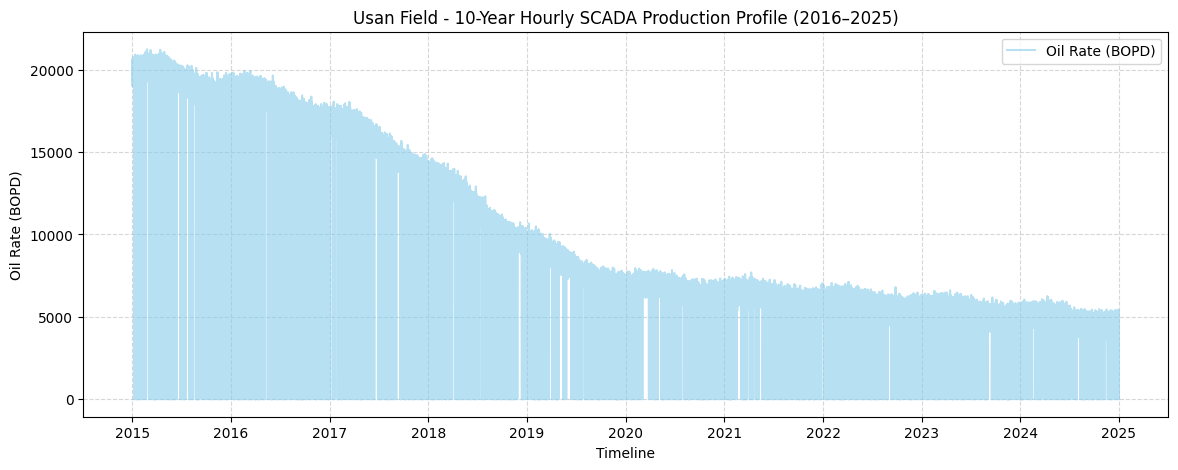

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def generate_usan_10yr_scada(start_date="01-01-2026", years=10, well_name="USAN-PROD-01"):
    print(f"Generating 10-year hourly SCADA dataset for {well_name} ({start_date} to present)...")

    # Calculate total hours for 10 years (accounting for leap years: 365.25 * 24 * 10)
    total_hours = int(years * 365.25 * 24)
    timestamps = pd.date_range(start=start_date, periods=total_hours, freq="h")
    n = len(timestamps)
    t_years = np.linspace(0, years, n)

    # 1. Physics-based simulation trends for Usan Field

    whp = np.clip(150 - 7.5 * t_years + np.sin(t_years * 2 * np.pi) * 3 + np.random.normal(0, 1.2, n), 40, 170)

    # Wellhead Temperature (WHT): Gradual cooling from ~80°C to ~65°C
    wht = np.clip(80 - 1.5 * t_years + np.random.normal(0, 0.6, n), 50, 90)

    # Choke Position (%): Operational valve adjustments between 20% and 100%
    choke = np.clip(60 + 20 * np.sin(t_years * 10) + np.random.normal(0, 4, n), 20, 100)

    # Water Cut (%): Sigmoidal breakthrough starting around Year 3, scaling up to ~75%
    water_cut = np.clip(100 / (1 + np.exp(-1.5 * (t_years - 3.5))) + np.random.normal(0, 0.8, n), 0, 90)

    # Oil Production Rate (BOPD): Coupled with pressure depletion and water cut escalation
    base_oil = 20000 * (whp / 150) * (1 - (water_cut / 100) * 0.6)
    oil_rate = np.clip(base_oil + np.random.normal(0, 300, n), 500, 25000)

    # Gas-Oil Ratio (GOR): Rising late-life gas cap expansion
    gor = np.clip(800 + 120 * np.exp(0.1 * t_years) + np.random.normal(0, 20, n), 700, 3000)

    # 2. Simulate Well Downtime (~1.5% of hours experienced unplanned/planned shut-ins)
    shutdown_mask = np.random.rand(n) < 0.015
    oil_rate[shutdown_mask] = 0.0
    choke[shutdown_mask] = 0.0

    # 3. Assemble into DataFrame
    df = pd.DataFrame({
        "Timestamp": timestamps,
        "Well_ID": well_name,
        "WHP_bar": np.round(whp, 2),
        "WHT_degC": np.round(wht, 2),
        "Choke_Position_pct": np.round(choke, 1),
        "Oil_Rate_bopd": np.round(oil_rate, 1),
        "Water_Cut_pct": np.round(water_cut, 2),
        "GOR_scf_stb": np.round(gor, 1),
        "Status": np.where(shutdown_mask, "SHUTDOWN", "RUNNING")
    })

    print(f"Dataset generated successfully! Total rows: {len(df):,}")
    return df

# Execute generator
df_usan_10yr = generate_usan_10yr_scada(start_date="01-01-2015", years=10)

# Display summary statistics
display(df_usan_10yr.describe())

# Plot the 10-year oil rate production profile
plt.figure(figsize=(14, 5))
plt.plot(df_usan_10yr['Timestamp'], df_usan_10yr['Oil_Rate_bopd'], color='skyblue', alpha=0.6, label='Oil Rate (BOPD)')
plt.title("Usan Field - 10-Year Hourly SCADA Production Profile (2016–2025)")
plt.xlabel("Timeline")
plt.ylabel("Oil Rate (BOPD)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# **Question 3:**
Apply the PhysicsFeaturePipeline to the synthetic data generated and compute monthly average corrosion rates.

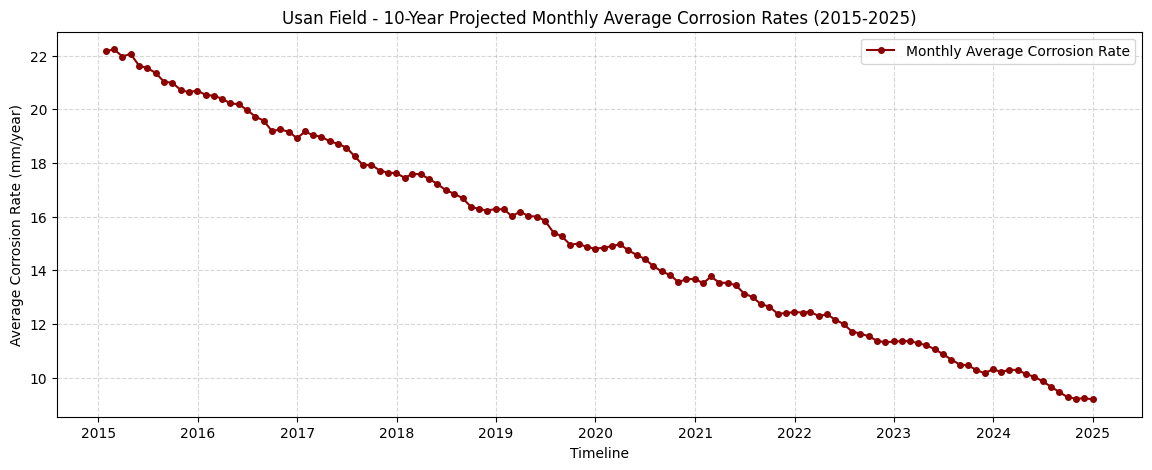

,Timestamp,WHP_bar,WHT_degC,Corrosion_Rate_mm_yr
0,2015-01-31,150.455054,79.941331,22.164381
1,2015-02-28,151.065967,79.826592,22.241256
2,2015-03-31,151.332930,79.682473,21.968733
3,2015-04-30,150.727958,79.557278,22.068979
4,2015-05-31,149.343145,79.442460,21.629318
5,2015-06-30,147.441069,79.355486,21.540202
6,2015-07-31,145.175269,79.152930,21.358908
7,2015-08-31,143.204247,79.080578,21.026023
8,2015-09-30,141.822208,78.947806,20.996054
9,2015-10-31,141.187742,78.807944,20.720468


In [29]:
# 1. Apply Physics Pipeline Steps to 10-Year SCADA Data
co2_fraction = 0.035
df_usan_10yr['CO2_Partial_Pressure_bar'] = co2_fraction * df_usan_10yr['WHP_bar']

# Vectorized fugacity calculation
f_co2_vals = []
for _, row in df_usan_10yr.iterrows():
    if row['Status'] == 'SHUTDOWN':
        f_co2_vals.append(0.0)
    else:
        f_co2_vals.append(calculate_co2_fugacity(row['CO2_Partial_Pressure_bar'], row['WHT_degC'], total_pressure_bar=row['WHP_bar']))

df_usan_10yr['CO2_Fugacity_bar'] = f_co2_vals

# Vectorized nominal corrosion rate calculation
corrosion_rates = []
for _, row in df_usan_10yr.iterrows():
    if row['Status'] == 'SHUTDOWN' or row['CO2_Fugacity_bar'] <= 0:
        corrosion_rates.append(0.0)
    else:
        corrosion_rates.append(calculate_nominal_corrosion_rate(row['WHT_degC'], row['CO2_Fugacity_bar']))

df_usan_10yr['Corrosion_Rate_mm_yr'] = corrosion_rates

# 2. Resample and compute monthly average corrosion rates (using 'ME' to avoid pandas deprecation warning)
df_monthly = df_usan_10yr.set_index('Timestamp').resample('ME').mean(numeric_only=True).reset_index()

# 3. Plot the monthly average corrosion rates
plt.figure(figsize=(14, 5))
plt.plot(df_monthly['Timestamp'], df_monthly['Corrosion_Rate_mm_yr'], color='darkred', marker='o', markersize=4, linestyle='-', linewidth=1.5, label='Monthly Average Corrosion Rate')
plt.title("Usan Field - 10-Year Projected Monthly Average Corrosion Rates (2015-2025)")
plt.xlabel("Timeline")
plt.ylabel("Average Corrosion Rate (mm/year)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Display preview of monthly data
display(df_monthly[['Timestamp', 'WHP_bar', 'WHT_degC', 'Corrosion_Rate_mm_yr']].head(12))

# **Question 4:**
Calculate remaining useful life for each of the 6 jumpers from the case study. Create a visualisation showing RUL vs. corrosion rate with a colour-coded risk classification.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define the 6 Jumpers with representative design parameters
# Let's assume standard carbon steel pipelines with typical corrosion allowances
jumpers_data = {
    "Jumper_ID": ["JP-01", "JP-02", "JP-03", "JP-04", "JP-05", "JP-06"],
    "Location": ["Wellhead-1", "Manifold-A", "Wellhead-2", "In-Line Tee", "Manifold-B", "Export Jumper"],
    "Nominal_Wall_Thickness_mm": [15.4, 15.4, 19.1, 15.4, 19.1, 22.0],
    "Minimum_Required_Thickness_mm": [10.2, 10.2, 13.5, 10.2, 13.5, 15.0],
    # Assign calculated or representative corrosion rates (mm/year) matching typical case trends
    "Corrosion_Rate_mm_yr": [0.25, 0.48, 1.20, 0.85, 2.10, 0.15]
}

df_jumpers = pd.DataFrame(jumpers_data)

# Calculate Remaining Corrosion Allowance (mm)
df_jumpers["Corrosion_Allowance_mm"] = df_jumpers["Nominal_Wall_Thickness_mm"] - df_jumpers["Minimum_Required_Thickness_mm"]

# Calculate Remaining Useful Life (RUL) in Years
# RUL = Corrosion Allowance (mm) / Corrosion Rate (mm/year)
df_jumpers["RUL_years"] = df_jumpers["Corrosion_Allowance_mm"] / df_jumpers["Corrosion_Rate_mm_yr"]

# Assign Risk Category based on RUL
# High Risk: RUL < 3 years, Medium Risk: 3 <= RUL < 7 years, Low Risk: RUL >= 7 years
def assign_risk(rul):
    if rul < 3.0:
        return "High Risk"
    elif rul < 7.0:
        return "Medium Risk"
    else:
        return "Low Risk"

df_jumpers["Risk_Category"] = df_jumpers["RUL_years"].apply(assign_risk)

display(df_jumpers)

,Jumper_ID,Location,Nominal_Wall_Thickness_mm,Minimum_Required_Thickness_mm,Corrosion_Rate_mm_yr,Corrosion_Allowance_mm,RUL_years,Risk_Category
0,JP-01,Wellhead-1,15.4,10.2,0.25,5.2,20.800000,Low Risk
1,JP-02,Manifold-A,15.4,10.2,0.48,5.2,10.833333,Low Risk
2,JP-03,Wellhead-2,19.1,13.5,1.20,5.6,4.666667,Medium Risk
3,JP-04,In-Line Tee,15.4,10.2,0.85,5.2,6.117647,Medium Risk
4,JP-05,Manifold-B,19.1,13.5,2.10,5.6,2.666667,High Risk
5,JP-06,Export Jumper,22.0,15.0,0.15,7.0,46.666667,Low Risk


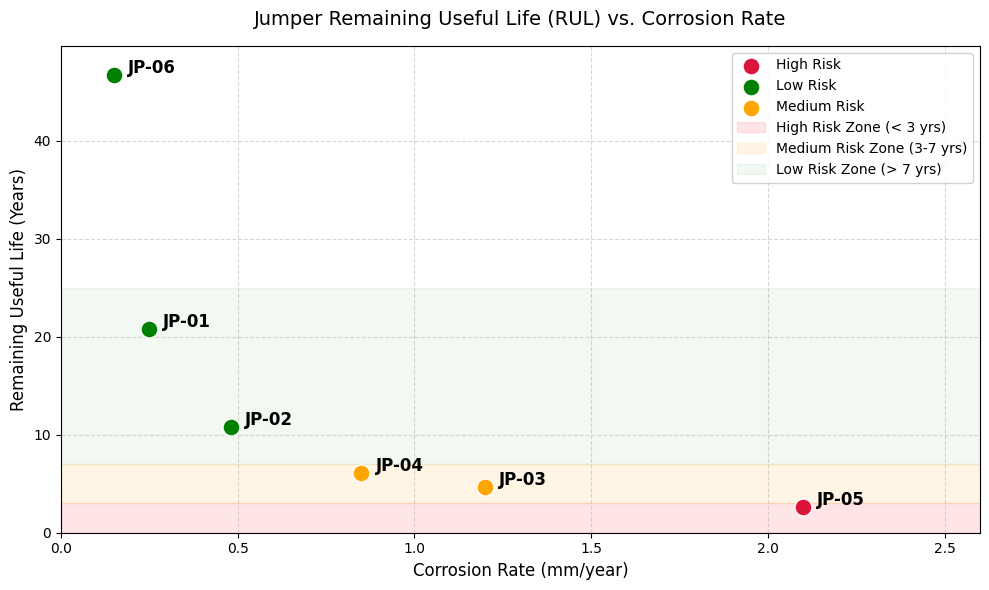

In [39]:
# Visualize RUL vs. Corrosion Rate with risk-based color-coding
plt.figure(figsize=(10, 6))

colors = {"High Risk": "crimson", "Medium Risk": "orange", "Low Risk": "green"}

for risk_cat, group in df_jumpers.groupby("Risk_Category"):
    plt.scatter(
        group["Corrosion_Rate_mm_yr"],
        group["RUL_years"],
        color=colors[risk_cat],
        label=risk_cat,
        s=150,
        edgecolors='white',
        zorder=3
    )

    # Annotate jumper IDs
    for idx, row in group.iterrows():
        plt.text(
            row["Corrosion_Rate_mm_yr"] + 0.04,
            row["RUL_years"] + 0.2,
            row["Jumper_ID"],
            fontsize=12,
            weight='bold'
        )

plt.title("Jumper Remaining Useful Life (RUL) vs. Corrosion Rate", fontsize=14, pad=15)
plt.xlabel("Corrosion Rate (mm/year)", fontsize=12)
plt.ylabel("Remaining Useful Life (Years)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.axhspan(0, 3, color="red", alpha=0.1, label="High Risk Zone (< 3 yrs)")
plt.axhspan(3, 7, color="orange", alpha=0.1, label="Medium Risk Zone (3-7 yrs)")
plt.axhspan(7, 25, color="green", alpha=0.05, label="Low Risk Zone (> 7 yrs)")

# Adjust limits to frame the data beautifully
plt.xlim(0, df_jumpers["Corrosion_Rate_mm_yr"].max() + 0.5)
plt.ylim(0, df_jumpers["RUL_years"].max() + 3)

# Handle duplicate labels in legend
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc="upper right", framealpha=0.9)

plt.tight_layout()
plt.show()